# Milestone 1 — Images as Matrices

Represent images as matrices and inspect grayscale/color pixels.

In [37]:

import os

if not os.path.exists("/content/svd-image-compression"):
    !git clone -q https://github.com/billygoattrain/svd-image-compression.git /content/svd-image-compression

%cd /content/svd-image-compression


/content/svd-image-compression


In [38]:
import sys, pathlib
from skimage import data
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
# Works after downloading/extracting the package, or from the project root in Colab.
project_root = pathlib.Path.cwd()
if not (project_root / "src").exists() and (project_root.parent / "src").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from compress import rank_k_approx, storage, compression_ratio, rel_error, predicted_error, k_for_error
(project_root / "figures").mkdir(exist_ok=True)
photo_path = project_root / "data" / "my_photo.png"
if photo_path.exists():
    P = np.array(Image.open(photo_path).convert("L"), dtype=float)
else:
    P = None
    print("Personal photograph not found; please add data/my_photo.png.")

## Grayscale image

Shape (512, 512) dtype uint8 min/max 0 255
[[200 200 200]
 [200 199 199]
 [199 199 199]]


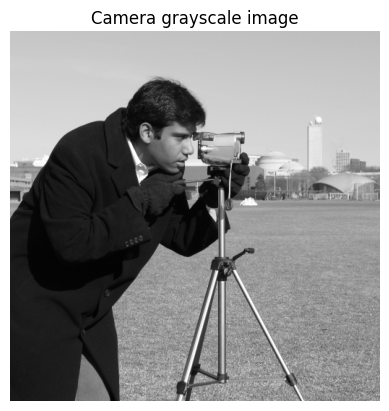

In [39]:
A=data.camera(); print("Shape",A.shape,"dtype",A.dtype,"min/max",A.min(),A.max()); print(A[:3,:3])
plt.imshow(A,cmap="gray",vmin=0,vmax=255);plt.title("Camera grayscale image");plt.axis("off");plt.show()

Each array entry is one pixel intensity; rows and columns correspond to image coordinates.

## Color images

Color shape (512, 512, 3)


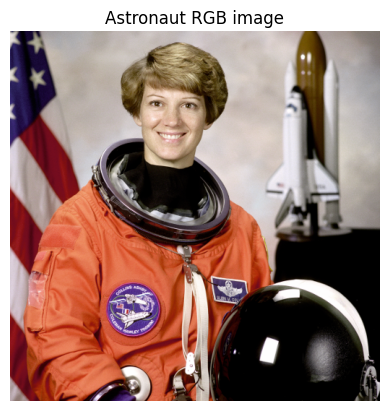

In [40]:
C=data.astronaut();print("Color shape",C.shape)
plt.imshow(C);plt.title("Astronaut RGB image");plt.axis("off");plt.show()

RGB images contain three color channels.

## Personal photo

Your photo (800, 600) pixel range 0.0 255.0


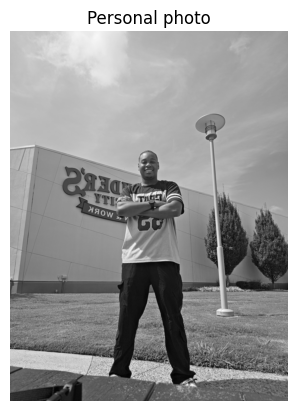

In [41]:
if P is not None:
    print("Your photo",P.shape,"pixel range",P.min(),P.max())
    plt.imshow(P,cmap="gray");plt.title("Personal photo");plt.axis("off");plt.show()

## Part B — Separate the color channels

A color image is three matrices. The third array index selects red (0), green (1), or blue (2).

RGB channel shapes: (512, 512) (512, 512) (512, 512)


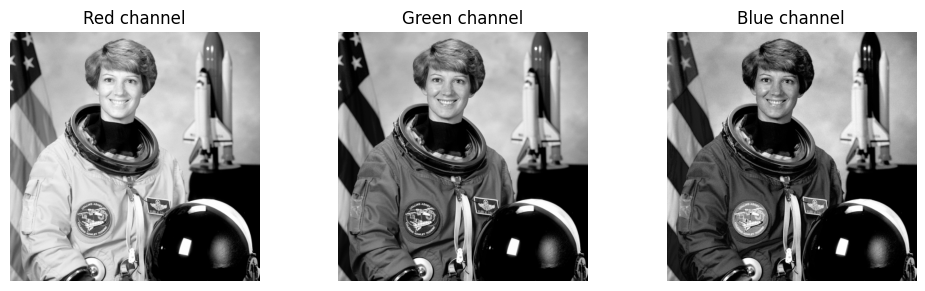

In [42]:
R, G, B = C[:, :, 0], C[:, :, 1], C[:, :, 2]
print("RGB channel shapes:", R.shape, G.shape, B.shape)
fig, axes = plt.subplots(1,3,figsize=(10,3))
for ax, channel, name in zip(axes,(R,G,B),("Red","Green","Blue")):
    ax.imshow(channel,cmap="gray",vmin=0,vmax=255)
    ax.set_title(name+" channel"); ax.axis("off")
plt.tight_layout();plt.show()

## Part C — The uint8 trap

An unsigned 8-bit integer can only store 0–255. Adding two values can wrap modulo 256, so convert image arrays to floating point before arithmetic.

In [43]:
x = np.array([200],dtype=np.uint8)
y = np.array([100],dtype=np.uint8)
print("uint8 200 + 100:", x+y)
print("float 200 + 100:", x.astype(float)+y.astype(float))

uint8 200 + 100: [44]
float 200 + 100: [300.]


## Part D — Tiny images and matrix rank

Rank counts independent row or column patterns. These visually different images all have rank 2.

Cross rank: 2
Gradient rank: 2
Checkerboard rank: 2


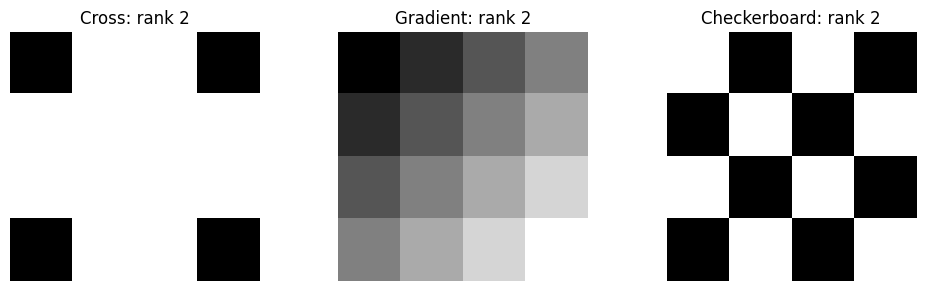

In [44]:
cross = np.array([[0,1,1,0],[1,1,1,1],[1,1,1,1],[0,1,1,0]])
gradient = np.array([[i+j for j in range(4)] for i in range(4)])
checker = np.array([[(i+j+1)%2 for j in range(4)] for i in range(4)])
fig,axes=plt.subplots(1,3,figsize=(10,3))
for ax, (name, M) in zip(axes,[("Cross",cross),("Gradient",gradient),("Checkerboard",checker)]):
    print(name,"rank:",np.linalg.matrix_rank(M))
    ax.imshow(M,cmap="gray",vmin=0,vmax=1 if name!="Gradient" else 6)
    ax.set_title(f"{name}: rank {np.linalg.matrix_rank(M)}");ax.axis("off")
plt.tight_layout();plt.show()

## Part D — A rank-1 stripe image

Every row of an outer product is a scalar multiple of the same vector, so two nonzero vectors produce a rank-1 matrix.

[[1 1 1 1]
 [0 0 0 0]
 [1 1 1 1]
 [0 0 0 0]] 
Rank: 1


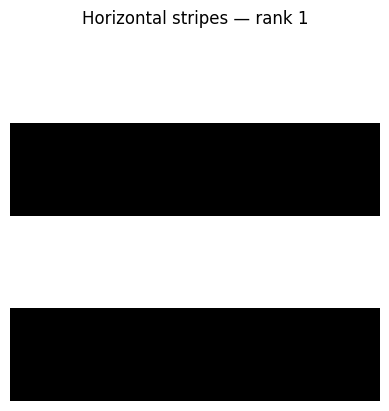

In [45]:
u = np.array([1,0,1,0]); v = np.array([1,1,1,1]); stripes=np.outer(u,v)
print(stripes,"\nRank:",np.linalg.matrix_rank(stripes))
plt.imshow(stripes,cmap="gray",vmin=0,vmax=1);plt.title("Horizontal stripes — rank 1");plt.axis("off");plt.show()

## Practice Exercise 1 — Pixel brightness

On the 0–255 grayscale scale, 18 is nearly black, 127 is medium gray, and 245 is nearly white. The brighter the pixel, the larger its intensity.

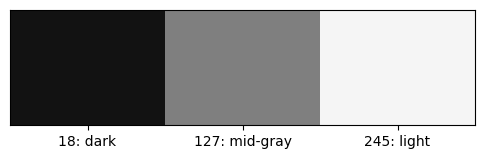

In [46]:
plt.figure(figsize=(6,1.5))
plt.imshow(np.array([[18,127,245]]),cmap="gray",vmin=0,vmax=255,aspect="auto")
plt.xticks([0,1,2],["18: dark","127: mid-gray","245: light"]);plt.yticks([]);plt.show()

## Practice Exercise 2 — Shape of a color image

A shape of (600, 900, 3) has 600 rows, 900 columns, and three color channels. It contains 600 × 900 × 3 = 1,620,000 numbers.

In [47]:
shape=(600,900,3)
print("rows, columns, channels:",shape)
print("Uncompressed array entries:",np.prod(shape))

rows, columns, channels: (600, 900, 3)
Uncompressed array entries: 1620000


## Practice Exercise 3 — Matrix slicing

The first slice selects rows 0–4 and the second selects columns 0–4, so `A[:5,:5]` displays the upper-left 5×5 block.

In [48]:
print("Top-left 5 by 5 camera pixels:\n",A[:5,:5])

Top-left 5 by 5 camera pixels:
 [[200 200 200 200 199]
 [200 199 199 200 199]
 [199 199 199 200 200]
 [200 200 199 199 199]
 [200 200 200 200 199]]


## Practice Exercise 4 — Avoiding overflow

250 + 20 = 270 mathematically, but uint8 wraps at 256 and gives 14. Floating-point addition returns the correct sum.

In [49]:
p=np.array([250],dtype=np.uint8);q=np.array([20],dtype=np.uint8)
print("uint8:",p+q)
print("float:",p.astype(float)+q.astype(float))

uint8: [14]
float: [270.]


## Practice Exercise 5 — Design a 4×4 image

I predict rank 2 because the matrix repeats just two linearly independent row patterns. The computation checks that prediction.

Predicted rank: 2; computed rank: 2


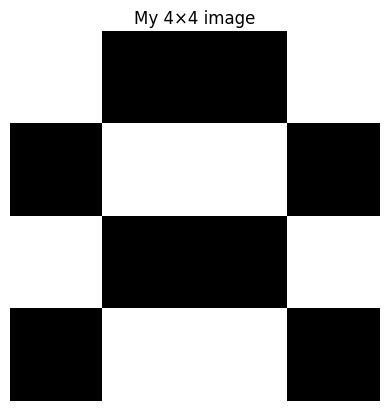

In [50]:
my_tiny=np.array([[1,0,0,1],[0,1,1,0],[1,0,0,1],[0,1,1,0]])
print("Predicted rank: 2; computed rank:",np.linalg.matrix_rank(my_tiny))
plt.imshow(my_tiny,cmap="gray",vmin=0,vmax=1);plt.title("My 4×4 image");plt.axis("off");plt.show()

## Practice Exercise 6 — A new rank-1 design

The vector `u` determines how strongly each row repeats `v`. Since all rows are multiples of the same nonzero row pattern, the rank is 1.

[[1 0 0 1]
 [0 0 0 0]
 [1 0 0 1]
 [1 0 0 1]] 
Rank: 1


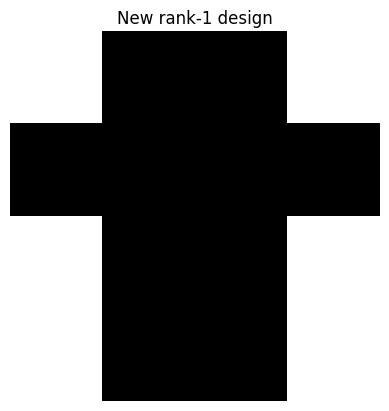

In [51]:
u2=np.array([1,0,1,1]);v2=np.array([1,0,0,1])
outer_image=np.outer(u2,v2)
print(outer_image,"\nRank:",np.linalg.matrix_rank(outer_image))
plt.imshow(outer_image,cmap="gray",vmin=0,vmax=1);plt.title("New rank-1 design");plt.axis("off");plt.show()

## Personal photograph note

My photograph is available at `data/my_photo.png`, converted to grayscale and displayed above. I am using it for the later SVD compression experiments. Anyone appearing in an image made public on GitHub should have consented to that publication.

### What we found

The grayscale camera image has dimensions of 512 × 512, meaning it contains 262,144 pixel intensity values ranging from 0 to 255. The RGB astronaut image has dimensions of 512 × 512 × 3 because each pixel contains red, green, and blue values.

My personal photograph was successfully converted into an 800 × 600 grayscale matrix. This experiment demonstrates how digital images can be represented as numerical matrices, allowing linear algebra operations such as the singular value decomposition (SVD) to be used for image compression.